In [1]:

!git clone https://github.com/bhaktiichandak/vehicle-detection-system.git


Cloning into 'vehicle-detection-system'...
remote: Enumerating objects: 61, done.
remote: Counting objects: 100% (61/61), done.
remote: Compressing objects: 100% (56/56), done.
remote: Total 61 (delta 6), reused 56 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (61/61), 27.18 MiB | 16.97 MiB/s, done.
Resolving deltas: 100% (6/6), done.


In [2]:

%cd /content/vehicle-detection-system
!ls -lh *.pt


/content/vehicle-detection-system
-rw-r--r-- 1 root root 6.0M Oct 10 17:45 best.pt
-rw-r--r-- 1 root root 6.0M Oct 10 17:45 last.pt


In [3]:

!pip install -q ultralytics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 27.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 5.0 MB/s eta 0:00:00


In [4]:

from ultralytics import YOLO

model = YOLO("/content/vehicle-detection-system/best.pt")

print("Model loaded successfully!")
print("Model classes:", model.names)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model loaded successfully!
Model classes: {0: 'car', 1: 'free'}


In [5]:
#Step 7 — Upload a traffic image
#Abhi sirf ek image par model test karenge.

from google.colab import files

uploaded = files.upload()


Saving Busy Noida Intersection Traffic.png to Busy Noida Intersection Traffic.png


In [7]:
#Step 8 — Run vehicle detection

image_path = "/content/vehicle-detection-system/Busy Noida Intersection Traffic.png"

results = model.predict(
    source=image_path,
    conf=0.25,
    save=False,
    verbose=False
)

print("Total detections:", len(results[0].boxes))
print("Model classes:", model.names)

Total detections: 7
Model classes: {0: 'car', 1: 'free'}


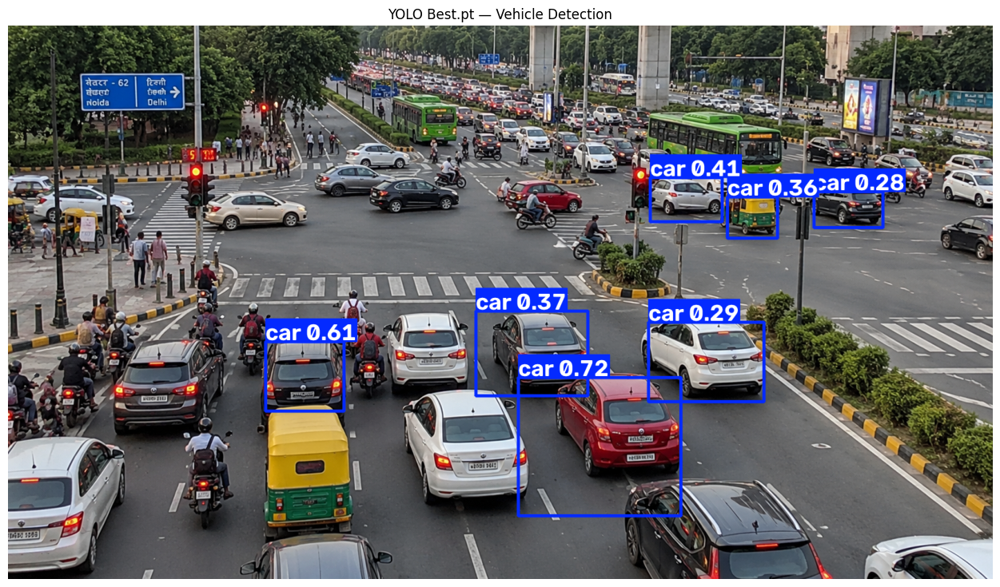

In [8]:

import cv2
import matplotlib.pyplot as plt

annotated = results[0].plot()
annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(16, 9))
plt.imshow(annotated)
plt.title("YOLO Best.pt — Vehicle Detection")
plt.axis("off")
plt.show()


In [9]:

for box in results[0].boxes:
    class_id = int(box.cls[0].item())
    confidence = float(box.conf[0].item())
    x1, y1, x2, y2 = box.xyxy[0].tolist()

    print(
        f"Class: {model.names[class_id]:<8} "
        f"Confidence: {confidence:.2f} "
        f"Box: {[round(v) for v in (x1, y1, x2, y2)]}"
    )


Class: car      Confidence: 0.72 Box: [867, 598, 1143, 834]
Class: car      Confidence: 0.61 Box: [438, 538, 571, 655]
Class: car      Confidence: 0.41 Box: [1090, 259, 1212, 334]
Class: car      Confidence: 0.37 Box: [795, 485, 985, 630]
Class: car      Confidence: 0.36 Box: [1222, 291, 1306, 361]
Class: car      Confidence: 0.29 Box: [1087, 505, 1284, 640]
Class: car      Confidence: 0.28 Box: [1368, 283, 1486, 343]


In [10]:

results_low = model.predict(
    source=image_path,
    conf=0.10,
    save=False,
    verbose=False
)

print("Detections at confidence 0.25:", len(results[0].boxes))
print("Detections at confidence 0.10:", len(results_low[0].boxes))


Detections at confidence 0.25: 7
Detections at confidence 0.10: 16


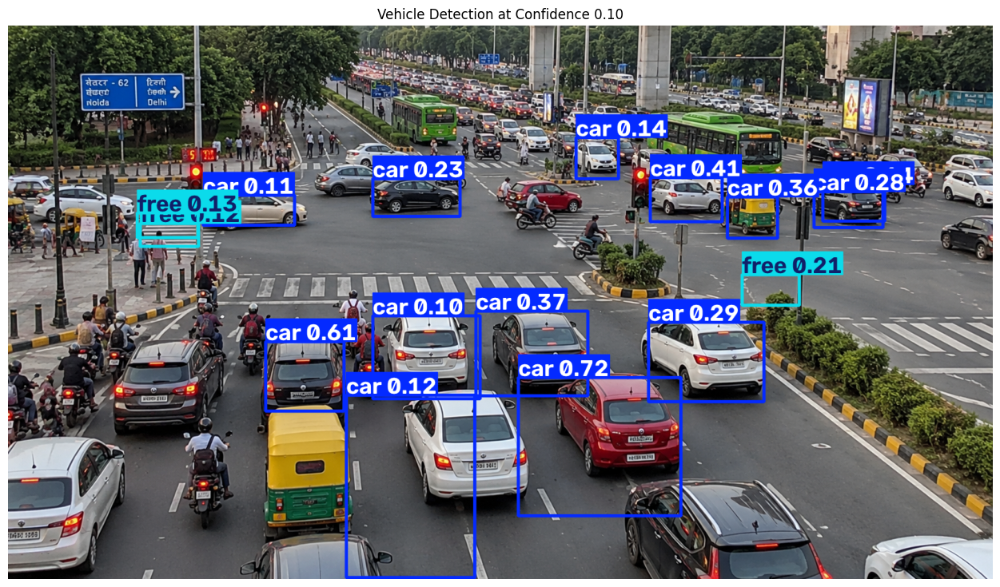

In [11]:

import matplotlib.pyplot as plt
import cv2

annotated_low = results_low[0].plot()
annotated_low = cv2.cvtColor(annotated_low, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(16, 9))
plt.imshow(annotated_low)
plt.title("Vehicle Detection at Confidence 0.10")
plt.axis("off")
plt.show()


In [12]:

car_results = model.predict(
    source=image_path,
    conf=0.10,
    classes=[0],
    save=False,
    verbose=False
)

print("Car detections only:", len(car_results[0].boxes))
print("Classes retained:", {
    model.names[int(box.cls[0].item())]
    for box in car_results[0].boxes
})


Car detections only: 13
Classes retained: {'car'}


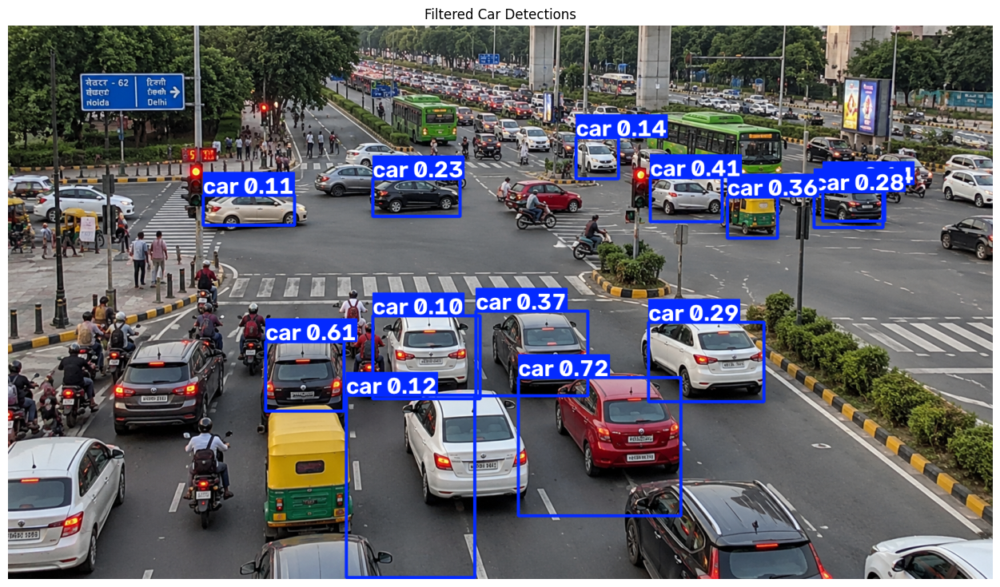

In [13]:

import cv2
import matplotlib.pyplot as plt

annotated = car_results[0].plot()
annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(16, 9))
plt.imshow(annotated)
plt.title("Filtered Car Detections")
plt.axis("off")
plt.show()


In [14]:

detections = []

for box in car_results[0].boxes:
    x1, y1, x2, y2 = box.xyxy[0].cpu().tolist()

    detections.append({
        "bbox": [x1, y1, x2, y2],
        "confidence": float(box.conf[0].cpu())
    })

print("Detections ready for density estimation:", len(detections))
print("First detection:", detections[0] if detections else "No detections")


Detections ready for density estimation: 13
First detection: {'bbox': [866.7386474609375, 598.25048828125, 1142.87548828125, 833.7359619140625], 'confidence': 0.7173569798469543}


In [15]:

detections = []

for box in car_results[0].boxes:
    x1, y1, x2, y2 = box.xyxy[0].cpu().tolist()

    detections.append({
        "bbox": [x1, y1, x2, y2],
        "confidence": float(box.conf[0].cpu())
    })

print("Detections ready:", len(detections))
print("First detection:", detections[0] if detections else "None")


Detections ready: 13
First detection: {'bbox': [866.7386474609375, 598.25048828125, 1142.87548828125, 833.7359619140625], 'confidence': 0.7173569798469543}


In [16]:

print(model.names)
print("Number of classes:", len(model.names))


{0: 'car', 1: 'free'}
Number of classes: 2


In [17]:

detections = []

for box in car_results[0].boxes:
    x1, y1, x2, y2 = box.xyxy[0].cpu().tolist()

    detections.append({
        "bbox": [x1, y1, x2, y2],
        "confidence": float(box.conf[0].cpu())
    })

print("Detections ready:", len(detections))
print("First detection:", detections[0] if detections else "None")


Detections ready: 13
First detection: {'bbox': [866.7386474609375, 598.25048828125, 1142.87548828125, 833.7359619140625], 'confidence': 0.7173569798469543}


In [20]:

import numpy as np
import cv2

# Temporary lane regions for our uploaded 1632 × 918 image.
# These are rough regions for an initial test, not calibrated road lanes.


height, width = results[0].orig_shape

lane_polygons = {
    "North": [(int(width*0.25), 0),
              (int(width*0.65), 0),
              (int(width*0.65), int(height*0.38)),
              (int(width*0.25), int(height*0.38))],

    "South": [(int(width*0.20), int(height*0.45)),
              (int(width*0.70), int(height*0.45)),
              (int(width*0.70), height),
              (int(width*0.20), height)],

    "East":  [(int(width*0.65), int(height*0.18)),
              (width, int(height*0.18)),
              (width, int(height*0.48)),
              (int(width*0.65), int(height*0.48))],

    "West":  [(0, int(height*0.18)),
              (int(width*0.25), int(height*0.18)),
              (int(width*0.25), int(height*0.48)),
              (0, int(height*0.48))]
}

print("Image width:", width)
print("Image height:", height)
print("Lane regions:", list(lane_polygons.keys()))


Image width: 1672
Image height: 941
Lane regions: ['North', 'South', 'East', 'West']


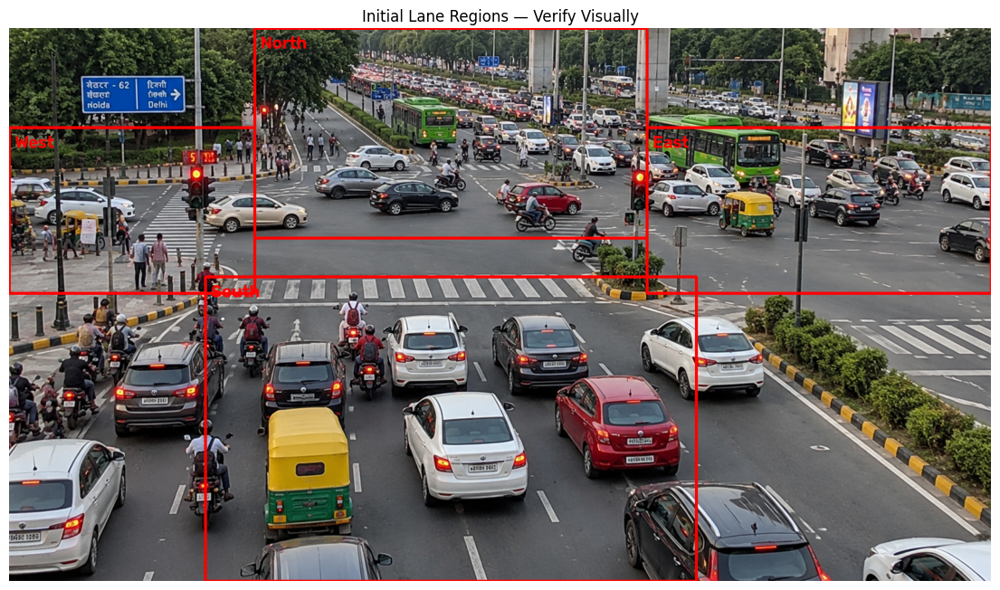

In [21]:

import matplotlib.pyplot as plt
import cv2
import numpy as np

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

overlay = image.copy()

for lane_name, points in lane_polygons.items():
    polygon = np.array(points, dtype=np.int32)
    cv2.polylines(
        overlay,
        [polygon],
        isClosed=True,
        color=(255, 0, 0),
        thickness=3
    )

    x, y = points[0]
    cv2.putText(
        overlay,
        lane_name,
        (x + 10, y + 35),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (255, 0, 0),
        2
    )

plt.figure(figsize=(14, 8))
plt.imshow(overlay)
plt.title("Initial Lane Regions — Verify Visually")
plt.axis("off")
plt.show()


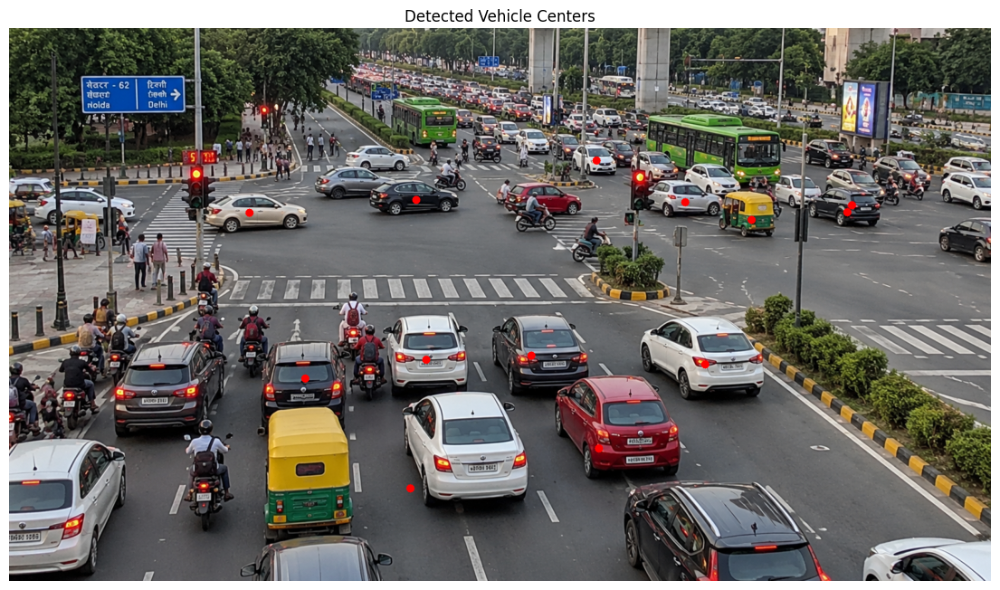

In [22]:

import matplotlib.pyplot as plt
import cv2

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

for detection in detections:
    x1, y1, x2, y2 = detection["bbox"]
    cx = int((x1 + x2) / 2)
    cy = int((y1 + y2) / 2)

    cv2.circle(image, (cx, cy), 7, (255, 0, 0), -1)

plt.figure(figsize=(14, 8))
plt.imshow(image)
plt.title("Detected Vehicle Centers")
plt.axis("off")
plt.show()


In [23]:

# Temporary horizontal regions for a rough count test
height, width = results[0].orig_shape

regions = {
    "Upper_Road": (0, int(height * 0.35)),
    "Intersection": (int(height * 0.35), int(height * 0.48)),
    "Lower_Road": (int(height * 0.48), height)
}

counts = {name: 0 for name in regions}

for d in detections:
    x1, y1, x2, y2 = d["bbox"]
    cy = (y1 + y2) / 2

    for name, (y_min, y_max) in regions.items():
        if y_min <= cy < y_max:
            counts[name] += 1
            break

for name, count in counts.items():
    print(f"{name}: {count} detected cars")


Upper_Road: 7 detected cars
Intersection: 0 detected cars
Lower_Road: 6 detected cars


In [24]:

!apt-get update -qq
!apt-get install -y sumo sumo-tools


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  binfmt-support fastjar fonts-roboto-unhinted jarwrapper javascript-common
  libboost-filesystem1.83.0 libcoin80t64 libcollada-dom2.5-dp0 libfox-1.6-0
  libgl2ps1.4 libglu1-mesa libjs-openlayers liblua5.2-0 libopenscenegraph161
  libopenthreads21 libpoppler-dev libpoppler-glib8t64 libpoppler-private-dev
  libpoppler134
Suggested packages:
  apache2 | lighttpd | httpd libopenal0a libsimage-dev libbullet2
Recommended packages:
  poppler-data
The following NEW packages will be installed:
  binfmt-support fastjar fonts-roboto-unhinted jarwrapper javascript-common
  libboost-filesystem1.83.0 libcoin80t64 libcollada-dom2.5-dp0 libfox-1.6-0
  libgl2ps1.4 libg

In [25]:

import os
import sys
import subprocess

os.environ["SUMO_HOME"] = "/usr/share/sumo"
sys.path.append("/usr/share/sumo/tools")

print("SUMO version:")
subprocess.run(["sumo", "--version"], check=True)

import traci
print("\nTraCI imported successfully!")


SUMO version:

TraCI imported successfully!


In [26]:

import os
import subprocess

os.makedirs("/content/traffic_sim", exist_ok=True)

subprocess.run([
    "netgenerate",
    "--grid",
    "--grid.x-number", "2",
    "--grid.y-number", "2",
    "--grid.x-length", "200",
    "--grid.y-length", "200",
    "--default.lanenumber", "2",
    "--output-file", "/content/traffic_sim/network.net.xml"
], check=True)

print("Network created successfully!")
print(os.path.getsize("/content/traffic_sim/network.net.xml"), "bytes")


Network created successfully!
10751 bytes


In [28]:

import sumolib

net = sumolib.net.readNet(
    "/content/traffic_sim/network.net.xml"
)

# Retrieve all lanes from the edges in the network
all_lanes = [lane for edge in net.getEdges() for lane in edge.getLanes()]

print("Network loaded successfully!")
print("Junctions:", len(net.getNodes()))
print("Road edges:", len(net.getEdges()))
print("Lanes:", len(all_lanes))

Network loaded successfully!
Junctions: 4
Road edges: 8
Lanes: 16


In [29]:

for edge in net.getEdges():
    if not edge.getID().startswith(":"):
        print(
            "Edge:", edge.getID(),
            "| From:", edge.getFromNode().getID(),
            "| To:", edge.getToNode().getID(),
            "| Lanes:", len(edge.getLanes())
        )


Edge: A0A1 | From: A0 | To: A1 | Lanes: 2
Edge: A0B0 | From: A0 | To: B0 | Lanes: 2
Edge: A1A0 | From: A1 | To: A0 | Lanes: 2
Edge: A1B1 | From: A1 | To: B1 | Lanes: 2
Edge: B0A0 | From: B0 | To: A0 | Lanes: 2
Edge: B0B1 | From: B0 | To: B1 | Lanes: 2
Edge: B1A1 | From: B1 | To: A1 | Lanes: 2
Edge: B1B0 | From: B1 | To: B0 | Lanes: 2


In [30]:

routes_xml = """<routes>
    <vType id="car" vClass="passenger" accel="2.6" decel="4.5" maxSpeed="13.89"/>
    <route id="route1" edges="A0A1 A1B1"/>
    <vehicle id="car1" type="car" route="route1" depart="0"/>
    <vehicle id="car2" type="car" route="route1" depart="2"/>
    <vehicle id="car3" type="car" route="route1" depart="4"/>
    <vehicle id="car4" type="car" route="route1" depart="6"/>
    <vehicle id="car5" type="car" route="route1" depart="8"/>
</routes>"""

routes_path = "/content/traffic_sim/routes.rou.xml"

with open(routes_path, "w") as f:
    f.write(routes_xml)

print("Route file created!")
print("Vehicles configured:", 5)


Route file created!
Vehicles configured: 5


In [31]:

import subprocess

result = subprocess.run(
    [
        "sumo",
        "-n", "/content/traffic_sim/network.net.xml",
        "-r", "/content/traffic_sim/routes.rou.xml",
        "--end", "100",
        "--no-step-log", "true"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)

if result.returncode == 0:
    print("SUMO simulation completed successfully!")
else:
    print(result.stderr[-3000:])


Return code: 0
SUMO simulation completed successfully!


In [32]:

import traci

sumo_cmd = [
    "sumo",
    "-n", "/content/traffic_sim/network.net.xml",
    "-r", "/content/traffic_sim/routes.rou.xml",
    "--no-step-log", "true"
]

traci.start(sumo_cmd)

for step in range(20):
    traci.simulationStep()

    if step in [0, 4, 9, 19]:
        print(f"\nSimulation time: {traci.simulation.getTime()} seconds")

        for lane_id in traci.lane.getIDList():
            if not lane_id.startswith(":"):
                count = traci.lane.getLastStepVehicleNumber(lane_id)

                if count > 0:
                    print(f"Lane {lane_id}: {count} vehicle(s)")

traci.close()


 Retrying in 1 seconds

Simulation time: 1.0 seconds
Lane A0A1_0: 1 vehicle(s)

Simulation time: 5.0 seconds
Lane A0A1_0: 2 vehicle(s)

Simulation time: 10.0 seconds
Lane A0A1_0: 4 vehicle(s)

Simulation time: 20.0 seconds
Lane A0A1_0: 4 vehicle(s)
Lane A1B1_0: 1 vehicle(s)


In [33]:

def classify_density(vehicle_count):
    if vehicle_count <= 1:
        return "LOW"
    elif vehicle_count <= 3:
        return "MEDIUM"
    else:
        return "HIGH"


lane_counts = {
    "A0A1_0": 4,
    "A1B1_0": 1,
    "B0B1_0": 0
}

for lane_id, count in lane_counts.items():
    density = classify_density(count)
    print(
        f"Lane: {lane_id} | "
        f"Vehicles: {count} | "
        f"Density: {density}"
    )


Lane: A0A1_0 | Vehicles: 4 | Density: HIGH
Lane: A1B1_0 | Vehicles: 1 | Density: LOW
Lane: B0B1_0 | Vehicles: 0 | Density: LOW


In [34]:

import traci

def classify_density(vehicle_count):
    if vehicle_count <= 1:
        return "LOW"
    elif vehicle_count <= 3:
        return "MEDIUM"
    return "HIGH"

traci.start([
    "sumo",
    "-n", "/content/traffic_sim/network.net.xml",
    "-r", "/content/traffic_sim/routes.rou.xml",
    "--no-step-log", "true"
])

for _ in range(20):
    traci.simulationStep()

print("\nLIVE TRAFFIC DENSITY")
print("-" * 40)

for lane_id in traci.lane.getIDList():
    if lane_id.startswith(":"):
        continue

    count = traci.lane.getLastStepVehicleNumber(lane_id)
    density = classify_density(count)

    print(f"{lane_id}: {count} vehicles -> {density}")

traci.close()


 Retrying in 1 seconds

LIVE TRAFFIC DENSITY
----------------------------------------
A0A1_0: 4 vehicles -> HIGH
A0A1_1: 0 vehicles -> LOW
A0B0_0: 0 vehicles -> LOW
A0B0_1: 0 vehicles -> LOW
A1A0_0: 0 vehicles -> LOW
A1A0_1: 0 vehicles -> LOW
A1B1_0: 1 vehicles -> LOW
A1B1_1: 0 vehicles -> LOW
B0A0_0: 0 vehicles -> LOW
B0A0_1: 0 vehicles -> LOW
B0B1_0: 0 vehicles -> LOW
B0B1_1: 0 vehicles -> LOW
B1A1_0: 0 vehicles -> LOW
B1A1_1: 0 vehicles -> LOW
B1B0_0: 0 vehicles -> LOW
B1B0_1: 0 vehicles -> LOW


In [35]:

import traci

traci.start([
    "sumo",
    "-n", "/content/traffic_sim/network.net.xml",
    "-r", "/content/traffic_sim/routes.rou.xml",
    "--no-step-log", "true"
])

for _ in range(20):
    traci.simulationStep()

print("LIVE LANE OCCUPANCY")
print("-" * 45)

for lane_id in traci.lane.getIDList():
    if lane_id.startswith(":"):
        continue

    count = traci.lane.getLastStepVehicleNumber(lane_id)
    occupancy = traci.lane.getLastStepOccupancy(lane_id)
    length = traci.lane.getLength(lane_id)

    print(
        f"{lane_id} | Vehicles: {count} | "
        f"Occupancy: {occupancy:.2f}% | "
        f"Length: {length:.1f} m"
    )

traci.close()


 Retrying in 1 seconds
LIVE LANE OCCUPANCY
---------------------------------------------
A0A1_0 | Vehicles: 4 | Occupancy: 0.11% | Length: 187.2 m
A0A1_1 | Vehicles: 0 | Occupancy: 0.00% | Length: 187.2 m
A0B0_0 | Vehicles: 0 | Occupancy: 0.00% | Length: 187.2 m
A0B0_1 | Vehicles: 0 | Occupancy: 0.00% | Length: 187.2 m
A1A0_0 | Vehicles: 0 | Occupancy: 0.00% | Length: 187.2 m
A1A0_1 | Vehicles: 0 | Occupancy: 0.00% | Length: 187.2 m
A1B1_0 | Vehicles: 1 | Occupancy: 0.03% | Length: 187.2 m
A1B1_1 | Vehicles: 0 | Occupancy: 0.00% | Length: 187.2 m
B0A0_0 | Vehicles: 0 | Occupancy: 0.00% | Length: 187.2 m
B0A0_1 | Vehicles: 0 | Occupancy: 0.00% | Length: 187.2 m
B0B1_0 | Vehicles: 0 | Occupancy: 0.00% | Length: 187.2 m
B0B1_1 | Vehicles: 0 | Occupancy: 0.00% | Length: 187.2 m
B1A1_0 | Vehicles: 0 | Occupancy: 0.00% | Length: 187.2 m
B1A1_1 | Vehicles: 0 | Occupancy: 0.00% | Length: 187.2 m
B1B0_0 | Vehicles: 0 | Occupancy: 0.00% | Length: 187.2 m
B1B0_1 | Vehicles: 0 | Occupancy: 0.00% |

In [36]:

import traci

traci.start([
    "sumo",
    "-n", "/content/traffic_sim/network.net.xml",
    "-r", "/content/traffic_sim/routes.rou.xml",
    "--no-step-log", "true"
])

for _ in range(20):
    traci.simulationStep()

print("LANE QUEUE ESTIMATION")
print("-" * 45)

for lane_id in traci.lane.getIDList():
    if lane_id.startswith(":"):
        continue

    vehicle_count = traci.lane.getLastStepVehicleNumber(lane_id)
    halting_count = traci.lane.getLastStepHaltingNumber(lane_id)
    mean_speed = traci.lane.getLastStepMeanSpeed(lane_id)

    if vehicle_count > 0:
        print(
            f"{lane_id} | Vehicles: {vehicle_count} | "
            f"Halting: {halting_count} | "
            f"Mean speed: {mean_speed:.2f} m/s"
        )

traci.close()


 Retrying in 1 seconds
LANE QUEUE ESTIMATION
---------------------------------------------
A0A1_0 | Vehicles: 4 | Halting: 0 | Mean speed: 12.72 m/s
A1B1_0 | Vehicles: 1 | Halting: 0 | Mean speed: 6.03 m/s


In [37]:

import traci

def classify_density(count, occupancy, mean_speed):
    if count == 0:
        return "EMPTY"
    if count >= 4 or occupancy >= 10 or mean_speed < 2:
        return "HIGH"
    if count >= 2 or occupancy >= 5 or mean_speed < 5:
        return "MEDIUM"
    return "LOW"

traci.start([
    "sumo",
    "-n", "/content/traffic_sim/network.net.xml",
    "-r", "/content/traffic_sim/routes.rou.xml",
    "--no-step-log", "true"
])

for _ in range(20):
    traci.simulationStep()

density_report = {}

for lane_id in traci.lane.getIDList():
    if lane_id.startswith(":"):
        continue

    count = traci.lane.getLastStepVehicleNumber(lane_id)
    occupancy = traci.lane.getLastStepOccupancy(lane_id)
    halting = traci.lane.getLastStepHaltingNumber(lane_id)
    mean_speed = traci.lane.getLastStepMeanSpeed(lane_id)

    density_report[lane_id] = {
        "vehicles": count,
        "occupancy_percent": occupancy,
        "halting_vehicles": halting,
        "mean_speed_mps": mean_speed,
        "density": classify_density(count, occupancy, mean_speed)
    }

traci.close()

for lane_id, data in density_report.items():
    if data["vehicles"] > 0:
        print(lane_id, "->", data)


 Retrying in 1 seconds
A0A1_0 -> {'vehicles': 4, 'occupancy_percent': 0.10683760683760685, 'halting_vehicles': 0, 'mean_speed_mps': 12.716231142934014, 'density': 'HIGH'}
A1B1_0 -> {'vehicles': 1, 'occupancy_percent': 0.02670940170940171, 'halting_vehicles': 0, 'mean_speed_mps': 6.032382915975526, 'density': 'LOW'}


In [38]:

import pandas as pd

density_df = pd.DataFrame.from_dict(
    density_report,
    orient="index"
)

density_df.index.name = "lane_id"
density_df = density_df.reset_index()

output_path = "/content/traffic_sim/density_report.csv"
density_df.to_csv(output_path, index=False)

print("Density report saved!")
print("File:", output_path)
print("Total lanes:", len(density_df))
print(density_df[density_df["vehicles"] > 0].to_string(index=False))


Density report saved!
File: /content/traffic_sim/density_report.csv
Total lanes: 16
lane_id  vehicles  occupancy_percent  halting_vehicles  mean_speed_mps density
 A0A1_0         4           0.106838                 0       12.716231    HIGH
 A1B1_0         1           0.026709                 0        6.032383     LOW


In [39]:

def classify_density(vehicle_count, occupancy_percent, mean_speed):
    if vehicle_count == 0:
        return "EMPTY"

    if occupancy_percent >= 20 or mean_speed < 2:
        return "HIGH"

    if occupancy_percent >= 10 or mean_speed < 5:
        return "MEDIUM"

    return "LOW"


for lane_id, data in density_report.items():
    data["density"] = classify_density(
        data["vehicles"],
        data["occupancy_percent"],
        data["mean_speed_mps"]
    )

for lane_id, data in density_report.items():
    if data["vehicles"] > 0:
        print(
            f"{lane_id}: {data['vehicles']} vehicles | "
            f"Speed: {data['mean_speed_mps']:.2f} m/s | "
            f"Occupancy: {data['occupancy_percent']:.2f}% | "
            f"Density: {data['density']}"
        )


A0A1_0: 4 vehicles | Speed: 12.72 m/s | Occupancy: 0.11% | Density: LOW
A1B1_0: 1 vehicles | Speed: 6.03 m/s | Occupancy: 0.03% | Density: LOW


In [40]:

import pandas as pd

density_df = pd.DataFrame.from_dict(
    density_report,
    orient="index"
)

density_df.index.name = "lane_id"
density_df = density_df.reset_index()

output_path = "/content/traffic_sim/density_report.csv"
density_df.to_csv(output_path, index=False)

print("Updated density report saved!")
print(density_df["density"].value_counts())
print("Path:", output_path)


Updated density report saved!
density
EMPTY    14
LOW       2
Name: count, dtype: int64
Path: /content/traffic_sim/density_report.csv


In [41]:

import pandas as pd

csv_path = "/content/traffic_sim/density_report.csv"
check_df = pd.read_csv(csv_path)

print("Columns:", check_df.columns.tolist())
print("\nDensity distribution:")
print(check_df["density"].value_counts())

print("\nSample records:")
print(check_df[check_df["vehicles"] > 0].to_string(index=False))


Columns: ['lane_id', 'vehicles', 'occupancy_percent', 'halting_vehicles', 'mean_speed_mps', 'density']

Density distribution:
density
EMPTY    14
LOW       2
Name: count, dtype: int64

Sample records:
lane_id  vehicles  occupancy_percent  halting_vehicles  mean_speed_mps density
 A0A1_0         4           0.106838                 0       12.716231     LOW
 A1B1_0         1           0.026709                 0        6.032383     LOW


In [42]:

heavy_routes_xml = """<routes>
    <vType id="car" vClass="passenger"
           accel="2.6" decel="4.5" maxSpeed="13.89"/>
    <route id="route1" edges="A0A1 A1B1"/>
"""

for i in range(40):
    heavy_routes_xml += (
        f'<vehicle id="car{i}" type="car" '
        f'route="route1" depart="{i}"/>\\n'
    )

heavy_routes_xml += "</routes>"

heavy_routes_path = "/content/traffic_sim/heavy_routes.rou.xml"

with open(heavy_routes_path, "w") as f:
    f.write(heavy_routes_xml)

print("Heavy traffic route file created!")
print("Vehicles configured:", 40)


Heavy traffic route file created!
Vehicles configured: 40


In [43]:

import traci

traci.start([
    "sumo",
    "-n", "/content/traffic_sim/network.net.xml",
    "-r", "/content/traffic_sim/heavy_routes.rou.xml",
    "--no-step-log", "true"
])

for _ in range(40):
    traci.simulationStep()

print("HEAVY TRAFFIC REPORT")
print("-" * 55)

for lane_id in traci.lane.getIDList():
    if lane_id.startswith(":"):
        continue

    count = traci.lane.getLastStepVehicleNumber(lane_id)
    occupancy = traci.lane.getLastStepOccupancy(lane_id)
    halting = traci.lane.getLastStepHaltingNumber(lane_id)
    speed = traci.lane.getLastStepMeanSpeed(lane_id)

    if count > 0:
        print(
            f"{lane_id} | Vehicles: {count} | "
            f"Occupancy: {occupancy:.2f}% | "
            f"Halting: {halting} | Speed: {speed:.2f} m/s"
        )

traci.close()


 Retrying in 1 seconds
HEAVY TRAFFIC REPORT
-------------------------------------------------------
A0A1_0 | Vehicles: 6 | Occupancy: 0.16% | Halting: 1 | Speed: 8.96 m/s
A0A1_1 | Vehicles: 1 | Occupancy: 0.03% | Halting: 0 | Speed: 10.11 m/s
A1B1_0 | Vehicles: 3 | Occupancy: 0.08% | Halting: 0 | Speed: 10.73 m/s
A1B1_1 | Vehicles: 2 | Occupancy: 0.05% | Halting: 0 | Speed: 12.00 m/s


In [44]:

def classify_density(vehicle_count, halting_count, mean_speed):
    if vehicle_count == 0:
        return "EMPTY"

    if halting_count >= 3 or mean_speed < 2:
        return "HIGH"

    if halting_count >= 1 or vehicle_count >= 5 or mean_speed < 5:
        return "MEDIUM"

    return "LOW"


traci.start([
    "sumo",
    "-n", "/content/traffic_sim/network.net.xml",
    "-r", "/content/traffic_sim/heavy_routes.rou.xml",
    "--no-step-log", "true"
])

for _ in range(40):
    traci.simulationStep()

print("HEAVY TRAFFIC DENSITY CLASSIFICATION")
print("-" * 50)

for lane_id in traci.lane.getIDList():
    if lane_id.startswith(":"):
        continue

    count = traci.lane.getLastStepVehicleNumber(lane_id)
    halting = traci.lane.getLastStepHaltingNumber(lane_id)
    speed = traci.lane.getLastStepMeanSpeed(lane_id)

    density = classify_density(count, halting, speed)

    if count > 0:
        print(
            f"{lane_id}: {count} vehicles | "
            f"Halting: {halting} | "
            f"Speed: {speed:.2f} m/s | "
            f"Density: {density}"
        )

traci.close()


 Retrying in 1 seconds
HEAVY TRAFFIC DENSITY CLASSIFICATION
--------------------------------------------------
A0A1_0: 6 vehicles | Halting: 1 | Speed: 8.96 m/s | Density: MEDIUM
A0A1_1: 1 vehicles | Halting: 0 | Speed: 10.11 m/s | Density: LOW
A1B1_0: 3 vehicles | Halting: 0 | Speed: 10.73 m/s | Density: LOW
A1B1_1: 2 vehicles | Halting: 0 | Speed: 12.00 m/s | Density: LOW


In [45]:

def get_lane_density_report():
    report = {}

    for lane_id in traci.lane.getIDList():
        if lane_id.startswith(":"):
            continue

        count = traci.lane.getLastStepVehicleNumber(lane_id)
        halting = traci.lane.getLastStepHaltingNumber(lane_id)
        speed = traci.lane.getLastStepMeanSpeed(lane_id)

        if count == 0:
            density = "EMPTY"
        elif halting >= 3 or speed < 2:
            density = "HIGH"
        elif halting >= 1 or count >= 5 or speed < 5:
            density = "MEDIUM"
        else:
            density = "LOW"

        report[lane_id] = {
            "vehicles": count,
            "halting": halting,
            "mean_speed_mps": round(speed, 2),
            "density": density
        }

    return report


print("Density module function created successfully!")


Density module function created successfully!


In [46]:

import traci

traci.start([
    "sumo",
    "-n", "/content/traffic_sim/network.net.xml",
    "-r", "/content/traffic_sim/heavy_routes.rou.xml",
    "--no-step-log", "true"
])

for _ in range(40):
    traci.simulationStep()

# Call Member 2's reusable density module
report = get_lane_density_report()

print("MEMBER 2: LIVE DENSITY MODULE")
print("-" * 45)

for lane_id, data in report.items():
    if data["vehicles"] > 0:
        print(f"{lane_id}: {data}")

traci.close()


 Retrying in 1 seconds
MEMBER 2: LIVE DENSITY MODULE
---------------------------------------------
A0A1_0: {'vehicles': 6, 'halting': 1, 'mean_speed_mps': 8.96, 'density': 'MEDIUM'}
A0A1_1: {'vehicles': 1, 'halting': 0, 'mean_speed_mps': 10.11, 'density': 'LOW'}
A1B1_0: {'vehicles': 3, 'halting': 0, 'mean_speed_mps': 10.73, 'density': 'LOW'}
A1B1_1: {'vehicles': 2, 'halting': 0, 'mean_speed_mps': 12.0, 'density': 'LOW'}


In [47]:

module_code = '''
def classify_density(count, halting, speed):
    if count == 0:
        return "EMPTY"
    elif halting >= 3 or speed < 2:
        return "HIGH"
    elif halting >= 1 or count >= 5 or speed < 5:
        return "MEDIUM"
    return "LOW"


def get_lane_density_report(traci):
    report = {}

    for lane_id in traci.lane.getIDList():
        if lane_id.startswith(":"):
            continue

        count = traci.lane.getLastStepVehicleNumber(lane_id)
        halting = traci.lane.getLastStepHaltingNumber(lane_id)
        speed = traci.lane.getLastStepMeanSpeed(lane_id)

        report[lane_id] = {
            "vehicles": count,
            "halting": halting,
            "mean_speed_mps": round(speed, 2),
            "density": classify_density(count, halting, speed)
        }

    return report
'''

module_path = "/content/traffic_sim/density_module.py"

with open(module_path, "w") as f:
    f.write(module_code)

print("Python module saved:", module_path)


Python module saved: /content/traffic_sim/density_module.py


In [48]:

import sys

sys.path.insert(0, "/content/traffic_sim")

from density_module import classify_density

print("Module imported successfully!")

print("Empty lane:", classify_density(0, 0, 0))
print("Low traffic:", classify_density(1, 0, 10))
print("Medium traffic:", classify_density(6, 1, 8.96))
print("High traffic:", classify_density(4, 3, 1.5))


Module imported successfully!
Empty lane: EMPTY
Low traffic: LOW
Medium traffic: MEDIUM
High traffic: HIGH


In [49]:

import sys
import traci

sys.path.insert(0, "/content/traffic_sim")

from density_module import get_lane_density_report

traci.start([
    "sumo",
    "-n", "/content/traffic_sim/network.net.xml",
    "-r", "/content/traffic_sim/heavy_routes.rou.xml",
    "--no-step-log", "true"
])

for _ in range(40):
    traci.simulationStep()

report = get_lane_density_report(traci)

print("SAVED MODULE + LIVE SUMO TEST")
print("-" * 45)

for lane_id, data in report.items():
    if data["vehicles"] > 0:
        print(f"{lane_id}: {data}")

traci.close()


 Retrying in 1 seconds
SAVED MODULE + LIVE SUMO TEST
---------------------------------------------
A0A1_0: {'vehicles': 6, 'halting': 1, 'mean_speed_mps': 8.96, 'density': 'MEDIUM'}
A0A1_1: {'vehicles': 1, 'halting': 0, 'mean_speed_mps': 10.11, 'density': 'LOW'}
A1B1_0: {'vehicles': 3, 'halting': 0, 'mean_speed_mps': 10.73, 'density': 'LOW'}
A1B1_1: {'vehicles': 2, 'halting': 0, 'mean_speed_mps': 12.0, 'density': 'LOW'}


In [50]:

import os
import zipfile

folder = "/content/traffic_sim"
zip_path = "/content/traffic_density_module.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(
        os.path.join(folder, "density_module.py"),
        arcname="density_module.py"
    )
    z.write(
        os.path.join(folder, "density_report.csv"),
        arcname="density_report.csv"
    )

print("Package created:", zip_path)
print("Size:", os.path.getsize(zip_path), "bytes")


Package created: /content/traffic_density_module.zip
Size: 780 bytes


In [51]:
from google.colab import files
files.download("/content/traffic_density_module.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [53]:
import os
import shutil

backup_folder = "/content/drive/MyDrive/Traffic_Project_Backup"
os.makedirs(backup_folder, exist_ok=True)

shutil.copy(
    "/content/traffic_density_module.zip",
    backup_folder
)

shutil.copy(
    "/content/traffic_sim/density_module.py",
    backup_folder
)

shutil.copy(
    "/content/traffic_sim/density_report.csv",
    backup_folder
)

print("Backup saved to Google Drive!")
print(backup_folder)

Backup saved to Google Drive!
/content/drive/MyDrive/Traffic_Project_Backup
